# QSAR — MMP (AID_720637), Random Split 8:1:1

Same pipeline as `qsar_mito.ipynb` (data loading -> ECFP4 + graph features ->
split + downsampling), adapted to:
- start from the already-cleaned `AID_720637_cleaned.csv` (score averaged per
  CID, outcome classified from the averaged score -- no re-deduplication here,
  that's already done)
- use an **8:1:1** train/validation/test split (per Ma et al.) instead of the
  mito notebook's 64:16:20

This notebook stops after the split + downsampling step. Model training
(RF/SVM/XGBoost/GNNs) runs separately on Wahab.

In [1]:
# ── Dependencies ──────────────────────────────────────────────────────────
import subprocess, sys
def _install(pkg):
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])
for pkg in ['rdkit', 'scikit-learn', 'matplotlib', 'seaborn', 'torch', 'torch-geometric']:
    try: __import__(pkg.replace('-', '_'))
    except ImportError: _install(pkg)
print('Dependencies OK.')

Dependencies OK.


In [2]:
# ── Imports ────────────────────────────────────────────────────────────────
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

from rdkit import Chem
from rdkit.Chem import AllChem, DataStructs

from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA

import torch
from torch_geometric.data import Data

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

Device: cpu


---
## Step 1 — Load Cleaned Data & Assign Labels

Starting from `AID_720637_cleaned.csv` (already deduped: score averaged per
CID, outcome classified from that averaged score). Only Active/Inactive
compounds are used for modeling -- Inconclusive is dropped.

In [3]:
# ── Load ──────────────────────────────────────────────────────────────────
df_raw = pd.read_csv(
    '/Users/yamini/Desktop/projects/qsar casepase/qsar_prediction/Rebuttal/Summary_1_models/cleaning/AID_720637_cleaned.csv',
    usecols=['PUBCHEM_CID', 'PUBCHEM_EXT_DATASOURCE_SMILES',
              'PUBCHEM_ACTIVITY_SCORE', 'PUBCHEM_ACTIVITY_OUTCOME'])
print(f'Raw rows : {len(df_raw):,}')
print(df_raw['PUBCHEM_ACTIVITY_OUTCOME'].value_counts())

Raw rows : 8,099
PUBCHEM_ACTIVITY_OUTCOME
Inactive        5080
Inconclusive    2162
Active           857
Name: count, dtype: int64


In [4]:
# ── Canonicalize SMILES ──────────────────────────────────────────────────────
def canonicalize(smi):
    try:
        mol = Chem.MolFromSmiles(str(smi))
        return Chem.MolToSmiles(mol) if mol else None
    except: return None

df_raw['csmi'] = df_raw['PUBCHEM_EXT_DATASOURCE_SMILES'].apply(canonicalize)
df = df_raw.dropna(subset=['csmi']).reset_index(drop=True)
print(f'After parse : {len(df):,}  (removed {len(df_raw)-len(df)} invalid SMILES)')

[13:46:26] WARNING: not removing hydrogen atom without neighbors


After parse : 8,099  (removed 0 invalid SMILES)


[13:46:26] WARNING: not removing hydrogen atom without neighbors
[13:46:26] WARNING: not removing hydrogen atom without neighbors


Active   (1): 857
Inactive (0): 5,080
Ratio       : 5.9:1


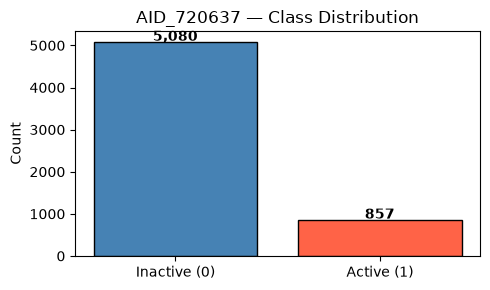

In [5]:
# ── Binary labels: Active -> 1, Inactive -> 0, Inconclusive -> drop ─────────
df = df[df['PUBCHEM_ACTIVITY_OUTCOME'].isin(['Active', 'Inactive'])].copy()
df['label'] = (df['PUBCHEM_ACTIVITY_OUTCOME'] == 'Active').astype(int)

n_act, n_ina = (df['label']==1).sum(), (df['label']==0).sum()
print(f'Active   (1): {n_act:,}')
print(f'Inactive (0): {n_ina:,}')
print(f'Ratio       : {n_ina/n_act:.1f}:1')

fig, ax = plt.subplots(figsize=(5,3))
bars = ax.bar(['Inactive (0)','Active (1)'],[n_ina,n_act],
              color=['steelblue','tomato'], edgecolor='black')
for b,v in zip(bars,[n_ina,n_act]):
    ax.text(b.get_x()+b.get_width()/2, v+30, f'{v:,}', ha='center', fontweight='bold')
ax.set_title('AID_720637 — Class Distribution')
ax.set_ylabel('Count')
plt.tight_layout(); plt.savefig('class_dist.png',dpi=150); plt.show()

---
## Step 2 — Feature Engineering

### 2A. Morgan Fingerprints (ECFP4) — for Classical ML
### 2B. Rich Atom/Bond Graph Features — for GNN

In [6]:
# ── Morgan ECFP4 (2048 bits) ─────────────────────────────────────────────
def smiles_to_ecfp4(smi, radius=2, n_bits=2048):
    mol = Chem.MolFromSmiles(smi)
    if mol is None: return None
    fp  = AllChem.GetMorganFingerprintAsBitVect(mol, radius, nBits=n_bits)
    arr = np.zeros(n_bits, dtype=np.float32)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr

fps = df['csmi'].apply(smiles_to_ecfp4)
valid = fps.notna()
df    = df[valid].reset_index(drop=True)
fps   = fps[valid]
X_fp  = np.vstack(fps.values)   # (N, 2048)
y_all = df['label'].values
print(f'Fingerprint matrix : {X_fp.shape}')
print(f'FP density         : {X_fp.mean():.4f}')

[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerat

[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerat

[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerat

Fingerprint matrix : (5937, 2048)
FP density         : 0.0141


[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerator
[13:46:27] DEPRECATION WARNING: please use MorganGenerat

In [7]:
# ── Rich Atom Features (27-dim) & Bond Features (6-dim) — for GNN ──────────
ATOM_SYMBOLS = [6,7,8,16,9,15,17,35,53]  # C N O S F P Cl Br I

def one_hot(val, choices):
    vec = [0]*len(choices)
    try: vec[choices.index(val)] = 1
    except ValueError: pass
    return vec

from rdkit.Chem import rdchem
HYBRID_MAP = {
    rdchem.HybridizationType.SP  : 0,
    rdchem.HybridizationType.SP2 : 1,
    rdchem.HybridizationType.SP3 : 2,
}

def atom_feat(atom):
    at_oh  = one_hot(atom.GetAtomicNum(), ATOM_SYMBOLS) + [0]
    hyb    = [0,0,0,0]
    hyb[HYBRID_MAP.get(atom.GetHybridization(), 3)] = 1
    deg    = min(atom.GetDegree(), 5)
    deg_oh = [0]*6; deg_oh[deg]=1
    fc     = atom.GetFormalCharge()
    fc_enc = [1 if fc<0 else 0, 1 if fc==0 else 0, 1 if fc>0 else 0]
    extras = [
        int(atom.GetIsAromatic()),
        int(atom.IsInRing()),
        min(atom.GetTotalNumHs(), 4) / 4.0,
        atom.GetMass() / 100.0
    ]
    return at_oh + deg_oh + fc_enc + hyb + extras  # 27-dim

BOND_TYPES = [rdchem.BondType.SINGLE, rdchem.BondType.DOUBLE,
              rdchem.BondType.TRIPLE, rdchem.BondType.AROMATIC]

def bond_feat(bond):
    bt = one_hot(bond.GetBondType(), BOND_TYPES)
    return bt + [int(bond.GetIsConjugated()), int(bond.IsInRing())]  # 6-dim

_mol = Chem.MolFromSmiles('CC(=O)O')
ATOM_DIM = len(atom_feat(_mol.GetAtomWithIdx(0)))
BOND_DIM  = len(bond_feat(_mol.GetBondWithIdx(0)))
print(f'Atom feature dim : {ATOM_DIM}')
print(f'Bond feature dim : {BOND_DIM}')

Atom feature dim : 27
Bond feature dim : 6


In [8]:
# ── Build Graph Dataset ───────────────────────────────────────────────────
def mol_to_graph(smi, label):
    mol = Chem.MolFromSmiles(smi)
    if mol is None: return None
    x = torch.tensor([atom_feat(a) for a in mol.GetAtoms()], dtype=torch.float)
    ei, ea = [], []
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        bf = bond_feat(bond)
        ei += [[i,j],[j,i]]
        ea += [bf, bf]
    if ei:
        edge_index = torch.tensor(ei, dtype=torch.long).t().contiguous()
        edge_attr  = torch.tensor(ea, dtype=torch.float)
    else:
        edge_index = torch.zeros((2,0), dtype=torch.long)
        edge_attr  = torch.zeros((0, BOND_DIM), dtype=torch.float)
    y = torch.tensor([label], dtype=torch.float)
    return Data(x=x, edge_index=edge_index, edge_attr=edge_attr, y=y)

graph_list = []
for smi, lbl in zip(df['csmi'].values, y_all):
    g = mol_to_graph(smi, lbl)
    if g: graph_list.append(g)

print(f'Graphs built: {len(graph_list):,}')
print(f'Example: {graph_list[0]}')

[13:46:27] WARNING: not removing hydrogen atom without neighbors


Graphs built: 5,937
Example: Data(x=[5, 27], edge_index=[2, 8], edge_attr=[8, 6], y=[1])


---
## Step 3 — 8:1:1 Random Split + Downsampling

Per Ma et al.: *"the input dataset is randomly split into 8:1:1, while 80% is
used for training, 10% is used for validation, and the last 10% is used for
testing."* Downsampling (to 1:1) is applied to the training set only.

In [9]:
# ── 10% External Test Split (8:1:1 -> test = 10% of total) ─────────────────
X_pool, X_test, y_pool, y_test = train_test_split(
    X_fp, y_all, test_size=0.10, stratify=y_all, random_state=SEED)

idx_all = np.arange(len(y_all))
idx_pool, idx_test = train_test_split(
    idx_all, test_size=0.10, stratify=y_all, random_state=SEED)

graphs_pool = [graph_list[i] for i in idx_pool]
graphs_test = [graph_list[i] for i in idx_test]

print(f'Pool : {len(y_pool):,}  (act={(y_pool==1).sum()}, ina={(y_pool==0).sum()})')
print(f'Test : {len(y_test):,}  (act={(y_test==1).sum()}, ina={(y_test==0).sum()})')

Pool : 5,343  (act=771, ina=4572)
Test : 594  (act=86, ina=508)


In [10]:
# ── Validation Split from Pool (10% of total = 1/9 of the 90% pool) ────────
X_tr_raw, X_val, y_tr_raw, y_val = train_test_split(
    X_pool, y_pool, test_size=1/9, stratify=y_pool, random_state=SEED)

pool_sub_idx = np.arange(len(y_pool))
tr_sub_idx, val_sub_idx = train_test_split(
    pool_sub_idx, test_size=1/9, stratify=y_pool, random_state=SEED)

graphs_val   = [graphs_pool[i] for i in val_sub_idx]
graphs_trraw = [graphs_pool[i] for i in tr_sub_idx]

print(f'Train-raw: {len(y_tr_raw):,}  (act={(y_tr_raw==1).sum()}, ina={(y_tr_raw==0).sum()})')
print(f'Val      : {len(y_val):,}  (act={(y_val==1).sum()},  ina={(y_val==0).sum()})')
print(f'Test     : {len(y_test):,}  (act={(y_test==1).sum()},  ina={(y_test==0).sum()})')

Train-raw: 4,749  (act=685, ina=4064)
Val      : 594  (act=86,  ina=508)
Test     : 594  (act=86,  ina=508)


In [11]:
# ── Downsampling on TRAIN ONLY ──────────────────────────────────────────────
act_idx_tr = np.where(y_tr_raw == 1)[0]
ina_idx_tr = np.where(y_tr_raw == 0)[0]
n_act_tr   = len(act_idx_tr)

rng = np.random.RandomState(SEED)
sampled_ina = rng.choice(ina_idx_tr, size=n_act_tr, replace=False)

train_idx = np.concatenate([act_idx_tr, sampled_ina])
rng.shuffle(train_idx)

X_train = X_tr_raw[train_idx]
y_train = y_tr_raw[train_idx]
graphs_train = [graphs_trraw[i] for i in train_idx]

print(f'Balanced TRAIN: {len(y_train):,}  act={(y_train==1).sum()} / ina={(y_train==0).sum()} (1:1)')
print(f'VAL  (real-world imbalance): {len(y_val):,}  ratio={(y_val==0).sum()/(y_val==1).sum():.1f}:1')
print(f'TEST (real-world imbalance): {len(y_test):,}  ratio={(y_test==0).sum()/(y_test==1).sum():.1f}:1')

Balanced TRAIN: 1,370  act=685 / ina=685 (1:1)
VAL  (real-world imbalance): 594  ratio=5.9:1
TEST (real-world imbalance): 594  ratio=5.9:1


Split summary (% of total)
  Train: 1,370 (23.1%)  act=685, ina=685
  Val  :   594 (10.0%)  act=86, ina=508
  Test :   594 (10.0%)  act=86, ina=508


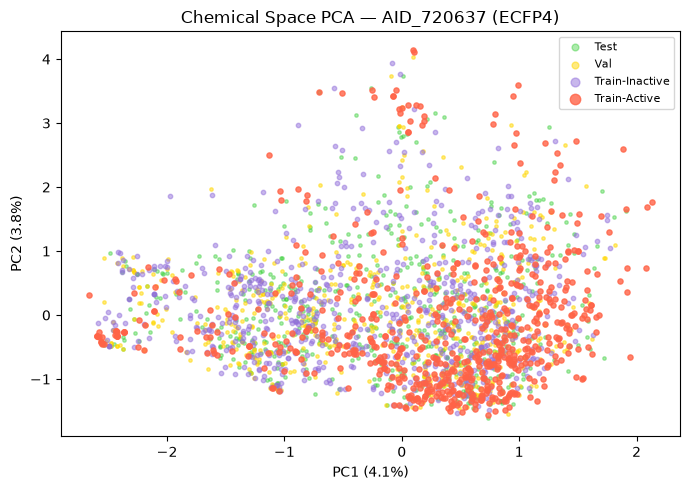

In [12]:
# ── Split Summary & Chemical Space PCA ───────────────────────────────────────
print('Split summary (% of total)')
for name, ys in [('Train',y_train),('Val',y_val),('Test',y_test)]:
    print(f'  {name:5s}: {len(ys):5,} ({100*len(ys)/len(y_all):.1f}%)  '
          f'act={(ys==1).sum()}, ina={(ys==0).sum()}')

pca = PCA(n_components=2, random_state=SEED)
pca.fit(X_train)
tr_p, va_p, te_p = pca.transform(X_train), pca.transform(X_val), pca.transform(X_test)

fig, ax = plt.subplots(figsize=(7,5))
ax.scatter(te_p[:,0], te_p[:,1], c='limegreen', s=6, alpha=0.4, label='Test')
ax.scatter(va_p[:,0], va_p[:,1], c='gold',      s=6, alpha=0.5, label='Val')
ax.scatter(tr_p[y_train==0,0], tr_p[y_train==0,1], c='mediumpurple', s=10, alpha=0.5, label='Train-Inactive')
ax.scatter(tr_p[y_train==1,0], tr_p[y_train==1,1], c='tomato',       s=14, alpha=0.8, label='Train-Active')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
ax.set_title('Chemical Space PCA — AID_720637 (ECFP4)')
ax.legend(markerscale=2, fontsize=8); plt.tight_layout()
plt.savefig('chem_space.png',dpi=150); plt.show()

---
**Stopping point.** Features + 8:1:1 split + downsampling are ready:
`X_train`/`y_train`/`graphs_train` (balanced 1:1), `X_val`/`y_val`/`graphs_val`,
`X_test`/`y_test`/`graphs_test` (both at natural imbalance). Model training
(RF/SVM/XGBoost hyperparameter tuning, GCN/GAT/GIN/SAGE) continues on Wahab
from this point, following the same Step 5/6 structure as `qsar_mito.ipynb`.